# 07KNN：距离、邻居和投票
## 一个和逻辑回归完全相反的思路
逻辑回归是**参数模型**：训练阶段要解一个优化问题，学出一组参数 w、b，训练完就可以把数据丢掉。
KNN 是**非参数模型 / 惰性学习（lazy learning）**：训练阶段什么都不算，只是把训练集存起来；真正干活发生在预测时刻——拿新样本去和所有训练样本比距离。
它的唯一假设可以概括成一句话：
> 特征空间里距离相近的样本，标签大概率相同。

这个假设看起来朴素，但它能拟合任意形状的决策边界，因此在中小规模、低维、样本分布不规则的任务上非常好用。

## 算法四步流程
给定待预测样本 `x0`、训练集、邻居数 `K`：

1. 计算 `x0` 到训练集中每一个样本的距离；
2. 按距离从小到大排序，取前 `K` 个样本（这 K 个就是“邻居”）；
3. 聚合邻居的标签：

    - 分类任务：多数投票（majority vote），票数最多的类别胜出；
    - 回归任务：取 K 个邻居标签的平均值或中位数；

4. 输出预测结果。

> 注意第 2 步是**全局排序**，没有“学到任何东西”。所以 KNN 的“训练”几乎没有成本，全部成本压在预测上。

## 距离度量：KNN的“灵魂参数”
KNN 的效果极度依赖“距离”的定义。常用四种：

**欧氏距离（L2，最常用）**

$$
d(x, x') = \\sqrt{\\sum\_{j=1}^{d} (x_j - x'\_j)^2}
$$

**曼哈顿距离（L1）**

$$
d(x, x') = \\sum\_{j=1}^{d} |x_j - x'\_j|
$$

**闵可夫斯基距离（统一形式）**

$$
d(x, x') = \\left( \\sum\_{j=1}^{d} |x_j - x'\_j|^{,q} \\right)^{1/q}
$$

`q = 1` 退化为曼哈顿，`q = 2` 退化为欧氏，`q` 趋于无穷退化为切比雪夫距离（各维差值取最大）。

**余弦相似度（用于文本、高维稀疏向量）**
$$
\\cos(x, x') = \\frac{x \\cdot x'}{|x| \\cdot |x'|}
$$

余弦看的是“方向是否一致”，不看长度，所以它对文档词频这类数据更合适。

### 关键推论：KNN 必须先做特征缩放

欧氏距离把每一维的差值平方后相加。如果一维取值 0~1，另一维取值 0~100000，那么大数那一维会**完全支配**距离，小数值那一维等于不存在。

这不是理论问题，实测非常明显。把二维数据第二维放大 1000 倍：

- 不标准化：测试准确率 0.8083
- 标准化后：测试准确率 0.9083

所以 Day1 讲的 `StandardScaler` 在这里不是“可选优化”，而是**必须**。同时要遵守 Day1 的规矩：只在训练集上 `fit`，测试集只 `transform`。

## K值怎么选
K 是 KNN 唯一的核心超参数，它直接控制模型的**复杂度**。

**K 太小（例如 K = 1）**

- 决策边界极度破碎，围着每个样本点“画圈”；
- 一个噪声点、一个错标样本就能带偏一片区域；
- 方差大，过拟合，训练集准确率接近 100%，测试集掉得厉害。

**K 太大（例如 K 接近样本总数）**

- 邻居离得越来越远，“近邻相似”的前提失效；
- 边界过度平滑，欠拟合；
- 类别不均衡时，少数类会被多数类彻底淹没（K=100 里 95 个是多数类，怎么投票都是多数类）。

**经验做法**

1. 二分类取奇数，避免平票（K=2 时 1:1 无法决策）；
2. 起步值可以取样本数的平方根；
3. 真正可靠的方式是**交叉验证扫描**：让 K 从 1 到 30 取奇数，每个 K 做 5 折交叉验证，取平均准确率最高的 K；
4. 曲线不一定是漂亮的 U 形，噪声大的数据会有明显波动，别只盯单个峰值，可结合多次随机种子或 `GridSearchCV` 复核。

本篇实测（`make_moons`, noise=0.25, 训练集 280 条）：最优 K = 17，5 折交叉验证准确率 0.9536。而 K=1 时只有 0.90 左右，说明这个数据上增大 K 确实抑制了噪声。

## 加权KNN：让近的邻居说话更响
标准 KNN 里 K 个邻居**一人一票，权重相同**。但距离 0.1 的邻居和距离 3.0 的邻居显然不该等同。

加权方案：

$$
\\text{weight}\_i = \\frac{1}{d(x_0, x_i) + \\varepsilon}
$$

或者用高斯核：

$$
\\text{weight}\_i = \\exp\\left(-\\frac{d(x_0, x_i)^2}{2\\sigma^2}\\right)
$$

分类时把票数换成“加权票数之和”，取最大的类别。sklearn 里就是 `KNeighborsClassifier(weights="distance")`。

### 加权不是“一开就变强”

加权本身也是超参数，要看数据和 K。实测两组：

**moons 数据（noise=0.25，主流程同一份）**

| K | uniform | distance |
| --- | --- | --- |
| 3 | 0.9000 | 0.9083 |
| 5 | 0.9083 | 0.9083 |
| 9 | 0.9167 | 0.9167 |
| 17 | 0.9250 | 0.9083 |

**make_classification 数据（300 条、2 维、每类 2 簇）**

| K | uniform | distance |
| --- | --- | --- |
| 3 | 0.9444 | 0.9444 |
| 5 | 0.9222 | 0.9444 |
| 9 | 0.9222 | 0.9444 |
| 17 | 0.9333 | 0.9444 |
结论很清楚：

- 邻居之间**距离差距明显**时（第二份数据有簇结构），加权收益显著，k=5 时提升 2.2 个百分点；
- 数据分布较均匀、K 又取得较大时（moons 的 k=17），加权反而掉 1.67 个百分点——因为它过度相信最近的少数几个点，把本应平滑的边界又拉碎了。

所以正确做法是**把 `weights` 和 `n_neighbors` 一起丢进交叉验证网格**，而不是默认加权一定更好。

In [1]:
# 代码复现
import numpy as np
from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

def compare_weights(X, y, tag):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )
    sc = StandardScaler()
    X_tr_s, X_te_s = sc.fit_transform(X_tr), sc.transform(X_te)
    print(tag)
    for k in [3, 5, 9, 17]:
        u = KNeighborsClassifier(k).fit(X_tr_s, y_tr).score(X_te_s, y_te)
        d = KNeighborsClassifier(k, weights="distance").fit(
            X_tr_s, y_tr
        ).score(X_te_s, y_te)
        print("  k=%2d uniform=%.4f distance=%.4f" % (k, u, d))

X1, y1 = make_moons(n_samples=400, noise=0.25, random_state=42)
compare_weights(X1, y1, "moons")

X2, y2 = make_classification(
    n_samples=300, n_features=2, n_informative=2,
    n_redundant=0, n_clusters_per_class=2, random_state=42
)
compare_weights(X2, y2, "make_classification")

moons
  k= 3 uniform=0.9000 distance=0.9083
  k= 5 uniform=0.9083 distance=0.9083
  k= 9 uniform=0.9167 distance=0.9167
  k=17 uniform=0.9250 distance=0.9083
make_classification
  k= 3 uniform=0.9444 distance=0.9444
  k= 5 uniform=0.9222 distance=0.9444
  k= 9 uniform=0.9222 distance=0.9444
  k=17 uniform=0.9333 distance=0.9444


## 计算复杂度与 KD 树
**训练复杂度**：`O(1)`，只做存储（实际还要建索引时会有开销）。

**预测复杂度**：暴力搜索是 `O(n × d)`，n 是训练样本数，d 是特征维数。这意味着一万条数据、一次预测就要算一万次距离；如果测试集也很大，预测会非常慢。

优化结构：

- **KD 树**：按维度切分空间，平均查询复杂度接近 `O(log n)`；
- **球树（Ball Tree）**：以球体划分，适合维度略高或非均匀分布；
- sklearn 通过 `algorithm="auto"` 自动选择，也可以手动指定 `"kd_tree"` 或 `"ball_tree"`。

### 维度灾难：KNN 在高中维会失效

维度升高时，任意两点之间的距离会趋于相同，“最近邻”和“最远邻”的区分度迅速消失。可以这样理解：

$$
\\lim\_{d \\to \\infty} \\frac{d\_{\\max} - d\_{\\min}}{d\_{\\min}} \\to 0
$$

距离失去区分能力，KNN 退化成随机猜。同时 KD 树在高维剪枝效率急剧下降，退化回线性扫描。

实践结论：**KNN 适合低维（大致 d ≤ 10~20）、中小规模数据；不适合做高维文本、图像原始像素的最近邻。**

## 优缺点与适用场景
| 维度 | KNN | 逻辑回归 |
| --- | --- | --- |
| 模型类型 | 非参数、惰性学习 | 参数模型 |
| 训练成本 | 极低（只存数据） | 需要迭代优化 |
| 预测成本 | 高（要扫全部训练样本） | 极低（一次矩阵乘法） |
| 决策边界 | 任意形状、非线性 | 只能是线性（超平面） |
| 特征缩放 | 必须做 | 强烈建议做 |
| 高维表现 | 差（维度灾难） | 相对稳定 |
| 可解释性 | 可看“是哪些邻居投的票” | 可看系数方向与大小 |
| 缺失值 | 不友好（距离算不出来） | 需先填充 |
| 类别不均衡 | 很敏感 | 可用 `class_weight` 缓解 |

**适合用 KNN 的场景**

- 样本量中等（几百到几万）、维度低；
- 决策边界明显非线性、又不值得上复杂模型；
- 需要快速拿到一个强 baseline；
- 推荐系统的“相似用户/相似物品”召回（本质就是近邻思想）。

**不适合的场景**

- 训练集几十万条以上、要求低延迟在线预测；
- 高维稀疏数据（文本 TF-IDF、图像原始像素）；
- 特征尺度混乱又不方便标准化；
- 类别严重不均衡且不做重采样。

手写 KNN 准确率：0.9083
sklearn 准确率：0.9083
两者预测一致比例：1.0000
最优 K = 17，交叉验证准确率 = 0.9536
uniform   测试准确率：0.9083
distance  测试准确率：0.9083


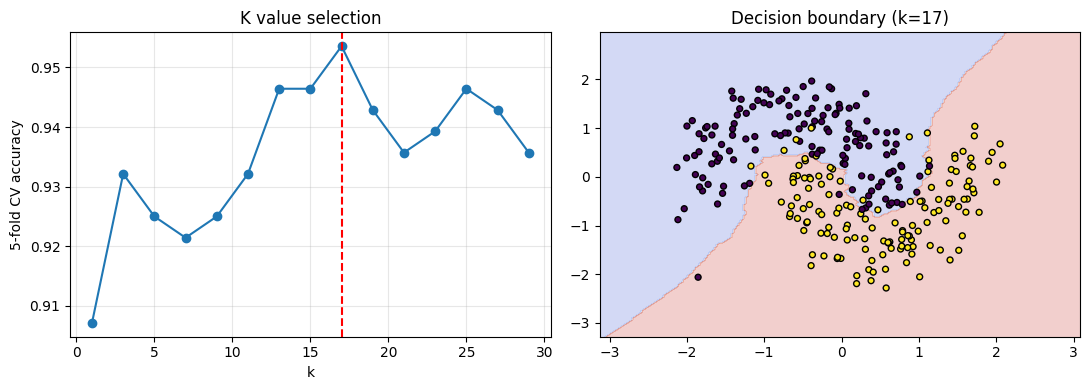

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# ---------- 1. 构造数据并划分 ----------
X, y = make_moons(n_samples=400, noise=0.25, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# ---------- 2. 特征缩放（只在训练集 fit） ----------
sc = StandardScaler()
X_tr_s = sc.fit_transform(X_tr)
X_te_s = sc.transform(X_te)

# ---------- 3. 手写 KNN ----------
def knn_predict(X_train, y_train, X_query, k=5, weighted=False):
    """支持等权投票与距离倒数加权投票"""
    preds = []
    for x in X_query:
        d = np.sqrt(np.sum((X_train - x) ** 2, axis=1))   # 欧氏距离
        idx = np.argsort(d)[:k]                            # 前 k 个最近邻
        labels = y_train[idx]
        if weighted:
            w = 1.0 / (d[idx] + 1e-8)
            score = {c: w[labels == c].sum() for c in np.unique(labels)}
            preds.append(max(score, key=score.get))
        else:
            preds.append(np.bincount(labels).argmax())     # 多数投票
    return np.array(preds)

pred_hand = knn_predict(X_tr_s, y_tr, X_te_s, k=5)
print("手写 KNN 准确率：%.4f" % (pred_hand == y_te).mean())

knn = KNeighborsClassifier(n_neighbors=5).fit(X_tr_s, y_tr)
print("sklearn 准确率：%.4f" % knn.score(X_te_s, y_te))
print("两者预测一致比例：%.4f" % (knn.predict(X_te_s) == pred_hand).mean())

# ---------- 4. K 值交叉验证扫描 ----------
k_list, acc_list = list(range(1, 31, 2)), []
for k in k_list:
    acc_list.append(
        cross_val_score(KNeighborsClassifier(k), X_tr_s, y_tr, cv=5).mean()
    )
best_k = k_list[int(np.argmax(acc_list))]
print("最优 K = %d，交叉验证准确率 = %.4f" % (best_k, max(acc_list)))

# ---------- 5. 等权 vs 距离加权 ----------
for wname in ["uniform", "distance"]:
    m = KNeighborsClassifier(n_neighbors=5, weights=wname).fit(X_tr_s, y_tr)
    print("%-9s 测试准确率：%.4f" % (wname, m.score(X_te_s, y_te)))

# ---------- 6. 可视化：K 曲线 + 决策边界 ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(k_list, acc_list, marker="o")
axes[0].axvline(best_k, ls="--", c="r")
axes[0].set_xlabel("k")
axes[0].set_ylabel("5-fold CV accuracy")
axes[0].set_title("K value selection")
axes[0].grid(alpha=0.3)

x_min, x_max = X_tr_s[:, 0].min() - 1, X_tr_s[:, 0].max() + 1
y_min, y_max = X_tr_s[:, 1].min() - 1, X_tr_s[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)
grid = np.c_[xx.ravel(), yy.ravel()]
m = KNeighborsClassifier(n_neighbors=best_k).fit(X_tr_s, y_tr)
zz = m.predict(grid).reshape(xx.shape)
axes[1].contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
axes[1].scatter(X_tr_s[:, 0], X_tr_s[:, 1], c=y_tr, edgecolor="k", s=18)
axes[1].set_title("Decision boundary (k=%d)" % best_k)
plt.tight_layout()
plt.show()

两个口径要分清楚：0.9536 是训练集内部 5 折交叉验证的平均准确率，0.9083 是外部测试集准确率。测试集更低是正常的，因为 CV 的分折数据都来自训练分布，而测试集是全新数据。用 K=17 的模型在测试集上实际得 0.9250。

In [3]:
# 尺寸敏感的独立小实验
import numpy as np
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = make_moons(n_samples=400, noise=0.25, random_state=42)
X[:, 1] *= 1000                              # 人为制造尺度差异
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

raw = KNeighborsClassifier(5).fit(Xtr, ytr)
std = make_pipeline(StandardScaler(), KNeighborsClassifier(5)).fit(Xtr, ytr)
print("不标准化：%.4f" % raw.score(Xte, yte))
print("标准化后：%.4f" % std.score(Xte, yte))

不标准化：0.8083
标准化后：0.9083


## 常见坑
1. **忘记标准化**，或者用全体数据（训练+测试）做 `fit_transform`，造成数据泄露。
2. **K 取偶数**，二分类时出现 1:1 平票，结果取决于实现细节。
3. **只看训练集准确率选 K**，K=1 几乎必然接近 100%，这是最典型的自欺。
4. **类别不均衡直接上 KNN**，预测结果会被多数类主导；要么重采样，要么换模型。
5. **拿 KNN 做高维文本或大数据在线预测**，延迟不可接受。
6. **把 KNN 当成“训练很慢”的模型**，反过来，它是训练极快、预测极慢，部署时要考虑缓存与索引。